In [1]:
# q2 - regressao polinomial bayesiana (grau 5)
# Levi Félix Barbosa - 579420

import numpy as np
import matplotlib.pyplot as plt

dados = np.loadtxt("polynomial_regression_data.csv", delimiter=",")
x, y = dados[:, 0], dados[:, 1]
N = len(x)
print(N, "pontos")

10 pontos


In [ ]:
# modelo com funcoes de base: y = Phi w + eps, eps ~ N(0, sigma2)
# phi(x_i) = [1, x_i, x_i^2, ..., x_i^5], P = 5
# priori: p(w) = N(w|m0, S0), com m0 = 0 e S0 = sigma_w2 * I
P = 5
M = P + 1
sigma2 = 0.04    # mesmo chute de ruido da q1
sigma_w2 = 200

def phi(x):
    return np.vander(x, M, increasing=True)

Phi = phi(x)
m0 = np.zeros(M)
S0 = sigma_w2 * np.eye(M)

In [3]:
# posteriori p(w|D) = N(w|mu, Sigma), formulas do resumo do algoritmo nos slides
A = np.linalg.inv(S0 @ Phi.T @ Phi + sigma2 * np.eye(M)) @ S0
mu = m0 + A @ Phi.T @ (y - Phi @ m0)
Sigma = S0 - A @ Phi.T @ Phi @ S0

print("media a posteriori:", mu.round(3))
print("desvio de cada peso:", np.sqrt(np.diag(Sigma)).round(3))

media a posteriori: [ 0.756  3.054 -7.607 -4.879  1.826  6.972]
desvio de cada peso: [ 0.796  4.775 10.125 10.448 11.476  7.031]


In [4]:
# preditiva: p(y*|x*) = N(y*|phi*^T mu, phi*^T Sigma phi* + sigma2)
def preditiva(xs, m, S):
    P = phi(xs)
    media = P @ m
    var = np.sum(P @ S * P, axis=1) + sigma2
    return media, np.sqrt(var)

xs = np.linspace(-0.1, 1.1, 200)

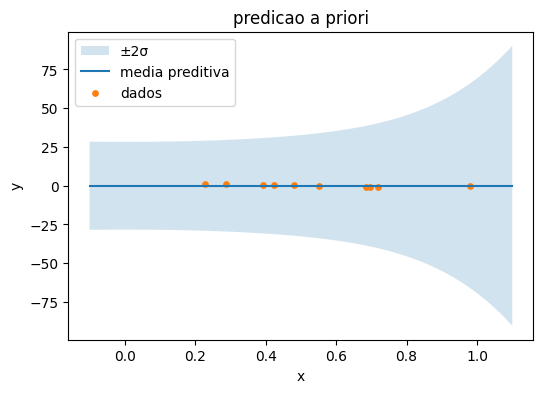

In [5]:
# a priori (mesma formula, trocando mu e Sigma por m0 e S0)
media, dp = preditiva(xs, m0, S0)

plt.figure(figsize=(6, 4))
plt.fill_between(xs, media - 2 * dp, media + 2 * dp, alpha=0.2, label="±2σ")
plt.plot(xs, media, label="media preditiva")
plt.scatter(x, y, s=15, label="dados")
plt.title("predicao a priori")
plt.xlabel("x")
plt.ylabel("y")
plt.legend()
plt.show()

# media zero de novo, mas a faixa explode perto de x=1 porque os termos
# x^4 e x^5 com pesos de desvio ~14 somam muita variancia. perto dos dados
# ela e tao larga que os pontos quase somem

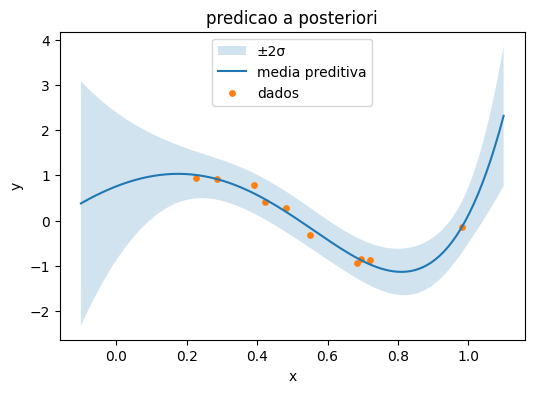

In [6]:
# a posteriori
media, dp = preditiva(xs, mu, Sigma)

plt.figure(figsize=(6, 4))
plt.fill_between(xs, media - 2 * dp, media + 2 * dp, alpha=0.2, label="±2σ")
plt.plot(xs, media, label="media preditiva")
plt.scatter(x, y, s=15, label="dados")
plt.title("predicao a posteriori")
plt.xlabel("x")
plt.ylabel("y")
plt.legend()
plt.show()

# a media segue o formato de seno dos dados. a faixa fica estreita onde tem
# ponto e abre nas pontas (x<0.2 e x>1), onde nao tem dado nenhum segurando
# o polinomio